# 13장. PatchCore 기반 제조 이미지 이상 탐지

「AI로 만드는 제조공정 품질관리 따라하기」 13장 실습 Notebook입니다.
Colab에서는 [런타임] → [런타임 유형 변경]에서 GPU(T4)를 선택하세요.

**데이터**: MVTec AD (CC BY-NC-SA 4.0, 비상업적 이용만 가능). 공식 사이트에서 이용 조건에 동의하고
`mvtec_anomaly_detection.tar.xz`(약 5GB)를 받아 Google Drive에 올려 두세요. 데이터 파일은 이 저장소에 없습니다.
출처: Bergmann et al., "MVTec AD — A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection", CVPR 2019.

실험 설계(결과를 보기 전에 정함)
- 15개 카테고리 모두: PatchCore(wide_resnet50_2, layer2+3, 코어셋 10%, k=9, 256×256)와
  기준 모델(같은 CNN의 이미지 전체 평균 특징 + 최근접 거리)을 비교
- 주 지표: 이미지 AUROC, 픽셀 AUROC, 픽셀 AUPRO (임계값이 필요 없는 지표)
- 자세히 보는 카테고리: bottle(물체·쉬움 예상), screw(물체·어려움 예상), carpet(질감)
- 임계값: 평가 이미지를 반으로 나눠 A에서 정하고 B에서 확인
- 코어셋 1%와 10% 비교(메모리·속도·성능)

In [1]:
import os
import sys
from pathlib import Path

# Colab은 Notebook마다 런타임이 따로라서, 14장 Notebook이 쓸 결과를 Drive의 이 폴더에 보관합니다
DRIVE_RUNS = "/content/drive/MyDrive/manufacturing-ai/13_runs"

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/03-defect-inspection/anomaly-detection
    !pip install -q anomalib==2.7.1
    from google.colab import drive
    drive.mount("/content/drive")
    TAR = "/content/drive/MyDrive/mvtec_anomaly_detection.tar.xz"      # Drive에 올린 위치에 맞게 바꾸세요
    !mkdir -p data/mvtec_ad && tar -xJf {TAR} -C data/mvtec_ad
    !mkdir -p {DRIVE_RUNS} results && cp -r {DRIVE_RUNS} results/     # 세션이 끊긴 뒤 다시 실행하면 끝난 카테고리를 건너뜀

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results/13_runs").mkdir(parents=True, exist_ok=True)

In [2]:
import json
import shutil
import time
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.ad_utils import (CATEGORIES, DATA_ROOT, FOCUS, TEXTURES, dataset_summary, env_info, global_knn_scores,
                          run_patchcore, threshold_holdout)

ENV = env_info()
print(ENV)

{'python': '3.12.9', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1', 'torch': '2.14.1+cu126', 'device': 'NVIDIA GeForce GTX 1080', 'anomalib': '2.7.1', 'torchvision': '0.29.1+cu126'}


## 13-1. MVTec AD 데이터의 특성

In [3]:
summary = dataset_summary()
print(summary.drop(columns="defect_types"))
print("합계:", summary[["train_good", "test_good", "test_defect"]].sum().to_dict())

               kind  train_good  test_good  test_defect  n_defect_types
category                                                               
bottle       object         209         20           63               3
cable        object         224         58           92               8
capsule      object         219         23          109               5
carpet      texture         280         28           89               5
grid        texture         264         21           57               5
hazelnut     object         391         40           70               4
leather     texture         245         32           92               5
metal_nut    object         220         22           93               4
pill         object         267         26          141               7
screw        object         320         41          119               5
tile        texture         230         33           84               5
toothbrush   object          60         12           30         

In [4]:
sizes = {c: Image.open(next((DATA_ROOT / c / "train" / "good").glob("*.png"))).size for c in CATEGORIES}
modes = {c: Image.open(next((DATA_ROOT / c / "train" / "good").glob("*.png"))).mode for c in CATEGORIES}
print("이미지 크기:", sizes)
print("색 모드:", modes)

이미지 크기: {'bottle': (900, 900), 'cable': (1024, 1024), 'capsule': (1000, 1000), 'carpet': (1024, 1024), 'grid': (1024, 1024), 'hazelnut': (1024, 1024), 'leather': (1024, 1024), 'metal_nut': (700, 700), 'pill': (800, 800), 'screw': (1024, 1024), 'tile': (840, 840), 'toothbrush': (1024, 1024), 'transistor': (1024, 1024), 'wood': (1024, 1024), 'zipper': (1024, 1024)}
색 모드: {'bottle': 'RGB', 'cable': 'RGB', 'capsule': 'RGB', 'carpet': 'RGB', 'grid': 'L', 'hazelnut': 'RGB', 'leather': 'RGB', 'metal_nut': 'RGB', 'pill': 'RGB', 'screw': 'L', 'tile': 'RGB', 'toothbrush': 'RGB', 'transistor': 'RGB', 'wood': 'RGB', 'zipper': 'L'}


In [5]:
# 결함 마스크 면적: 결함이 이미지에서 차지하는 비율
area = {}
for c in FOCUS:
    fr = [np.asarray(Image.open(p)).astype(bool).mean() for p in (DATA_ROOT / c / "ground_truth").glob("*/*.png")]
    area[c] = {"median_pct": round(float(np.median(fr)) * 100, 2), "min_pct": round(float(np.min(fr)) * 100, 3),
               "max_pct": round(float(np.max(fr)) * 100, 1)}
print("결함 면적 비율(%):", area)

결함 면적 비율(%): {'bottle': {'median_pct': 5.72, 'min_pct': 0.576, 'max_pct': 27.4}, 'screw': {'median_pct': 0.29, 'min_pct': 0.099, 'max_pct': 1.0}, 'carpet': {'median_pct': 1.48, 'min_pct': 0.165, 'max_pct': 8.0}}


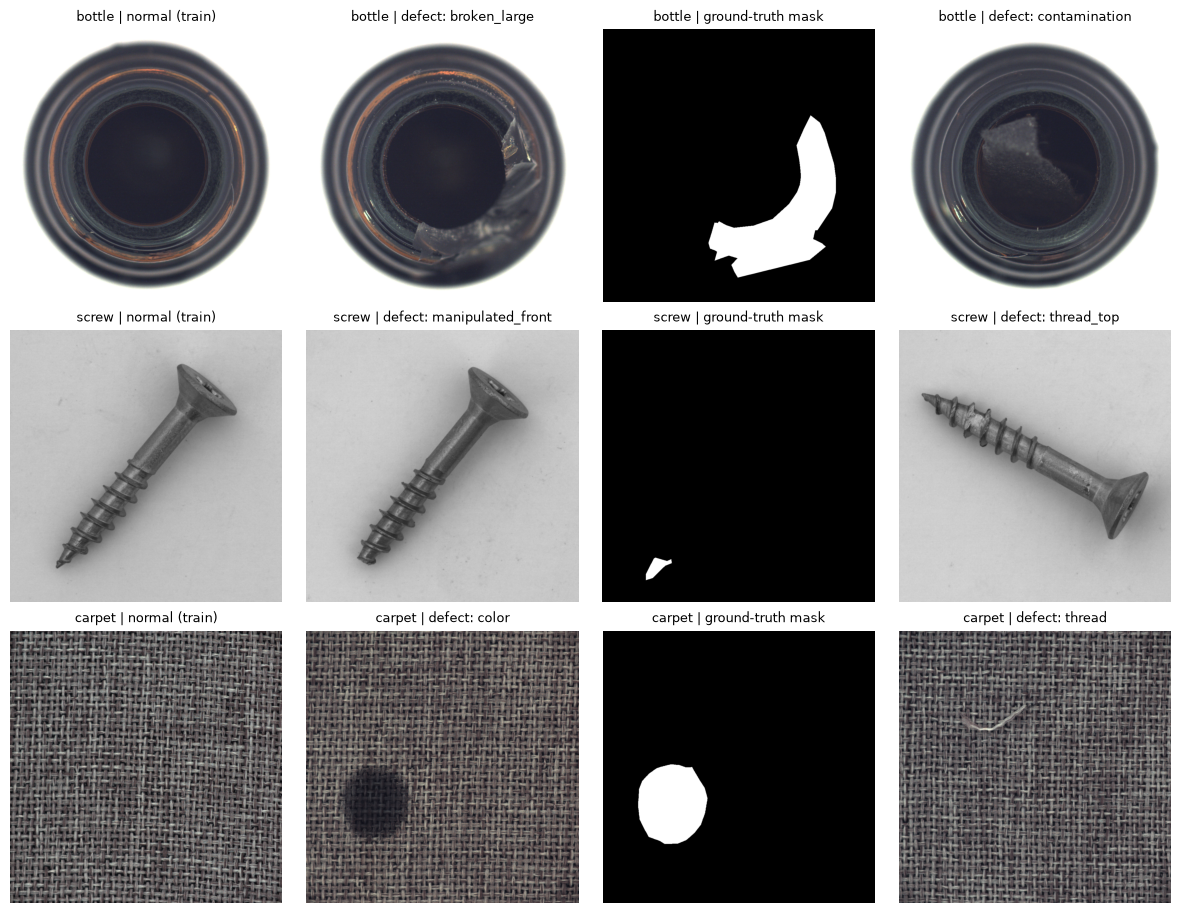

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9.2))
for r, c in enumerate(FOCUS):
    good = sorted((DATA_ROOT / c / "train" / "good").glob("*.png"))[0]
    dtype = summary.loc[c, "defect_types"].split(", ")[0]
    bad = sorted((DATA_ROOT / c / "test" / dtype).glob("*.png"))[0]
    mask = DATA_ROOT / c / "ground_truth" / dtype / f"{bad.stem}_mask.png"
    dtype2 = summary.loc[c, "defect_types"].split(", ")[-1]
    bad2 = sorted((DATA_ROOT / c / "test" / dtype2).glob("*.png"))[0]
    for ax, (t, p) in zip(axes[r], [("normal (train)", good), (f"defect: {dtype}", bad), ("ground-truth mask", mask),
                                    (f"defect: {dtype2}", bad2)]):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(f"{c} | {t}", fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig("results/13_examples.png", dpi=90)
plt.show()

## 13-2. PatchCore와 기준 모델 실행 (15개 카테고리)

끝난 카테고리는 `results/13_runs/`에 저장해 두고, 다시 실행하면 건너뜁니다.

In [7]:
def npz_ok(p):
    try:
        with zipfile.ZipFile(p) as z:
            return z.testzip() is None
    except (OSError, zipfile.BadZipFile):
        return False


def cached(name, fn, need=()):
    f_json, f_csv = Path(f"results/13_runs/{name}.json"), Path(f"results/13_runs/{name}.csv")
    if f_json.exists() and f_csv.exists() and all(npz_ok(p) for p in need):
        try:                                           # 복사 중 끊겨 깨진 파일이면 다시 계산
            out, scores = json.loads(f_json.read_text(encoding="utf-8")), pd.read_csv(f_csv)
            if len(scores) > 0:
                return out, scores
        except (ValueError, pd.errors.EmptyDataError, pd.errors.ParserError):
            pass
        print(f"{name}: 저장 파일이 손상되어 다시 계산합니다")
    out, scores = fn()
    tmp = f_csv.with_suffix(".tmp")                    # 임시 파일에 쓴 뒤 이름을 바꿔, 반쯤 쓴 파일이 남지 않게 함
    scores.to_csv(tmp, index=False); tmp.replace(f_csv)
    tmp.write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8"); tmp.replace(f_json)
    return out, scores


def patchcore_job(c, ratio):
    def fn():
        out, scores, maps = run_patchcore(c, coreset_ratio=ratio, keep_maps=(c in FOCUS and ratio == 0.1))
        if maps:
            f_npz = Path(f"results/13_runs/{c}_maps.npz")
            with open(f_npz.with_suffix(".tmp"), "wb") as f:
                np.savez_compressed(f, **{k.replace("/", "__"): v for k, v in maps.items()})
            f_npz.with_suffix(".tmp").replace(f_npz)
        return out, scores
    return fn


def knn_job(c):
    def fn():
        from sklearn.metrics import roc_auc_score
        t0 = time.perf_counter()
        scores = global_knn_scores(c)
        return {"category": c, "image_AUROC": round(float(roc_auc_score(scores["label"], scores["score"])), 4),
                "sec": round(time.perf_counter() - t0, 1)}, scores
    return fn


results, all_scores = {"patchcore_10": {}, "patchcore_1": {}, "global_knn": {}}, {}
for c in CATEGORIES:
    t0 = time.perf_counter()
    maps = [f"results/13_runs/{c}_maps.npz"] if c in FOCUS else []   # 이상 지도도 있어야 끝난 것으로 봄
    results["patchcore_10"][c], all_scores[c] = cached(f"{c}_pc10", patchcore_job(c, 0.1), need=maps)
    results["patchcore_1"][c], _ = cached(f"{c}_pc1", patchcore_job(c, 0.01))
    results["global_knn"][c], _ = cached(f"{c}_knn", knn_job(c))
    r = results["patchcore_10"][c]
    print(f"{c:11s} PatchCore 이미지 {r['image_AUROC']:.3f} 픽셀 {r['pixel_AUROC']:.3f} PRO {r['pixel_AUPRO']:.3f} "
          f"| 기준 이미지 {results['global_knn'][c]['image_AUROC']:.3f} | 학습 {r['fit_sec']:.0f}초 "
          f"({time.perf_counter() - t0:.0f}초)")
    if "google.colab" in sys.modules:                  # 카테고리마다 Drive에 복사 (세션이 끊겨도 이어서, 14장에서 불러 씀)
        shutil.copytree("results/13_runs", DRIVE_RUNS, dirs_exist_ok=True)

bottle      PatchCore 이미지 1.000 픽셀 0.986 PRO 0.945 | 기준 이미지 0.991 | 학습 89초 (146초)


cable       PatchCore 이미지 0.988 픽셀 0.985 PRO 0.930 | 기준 이미지 0.814 | 학습 110초 (213초)


capsule     PatchCore 이미지 0.993 픽셀 0.990 PRO 0.934 | 기준 이미지 0.925 | 학습 112초 (206초)


carpet      PatchCore 이미지 0.987 픽셀 0.991 PRO 0.948 | 기준 이미지 0.525 | 학습 176초 (276초)


grid        PatchCore 이미지 0.988 픽셀 0.983 PRO 0.913 | 기준 이미지 0.502 | 학습 137초 (196초)


hazelnut    PatchCore 이미지 1.000 픽셀 0.988 PRO 0.954 | 기준 이미지 0.908 | 학습 305초 (426초)


... (5 outputs left out)

toothbrush  PatchCore 이미지 0.917 픽셀 0.989 PRO 0.884 | 기준 이미지 0.950 | 학습 13초 (43초)


transistor  PatchCore 이미지 0.994 픽셀 0.973 PRO 0.946 | 기준 이미지 0.868 | 학습 106초 (185초)


wood        PatchCore 이미지 0.987 픽셀 0.931 PRO 0.886 | 기준 이미지 0.649 | 학습 135초 (212초)


zipper      PatchCore 이미지 0.979 픽셀 0.982 PRO 0.934 | 기준 이미지 0.928 | 학습 125초 (201초)


In [8]:
table = pd.DataFrame({
    "kind": ["texture" if c in TEXTURES else "object" for c in CATEGORIES],
    "knn_image": [results["global_knn"][c]["image_AUROC"] for c in CATEGORIES],
    "pc_image": [results["patchcore_10"][c]["image_AUROC"] for c in CATEGORIES],
    "pc_pixel": [results["patchcore_10"][c]["pixel_AUROC"] for c in CATEGORIES],
    "pc_pro": [results["patchcore_10"][c]["pixel_AUPRO"] for c in CATEGORIES],
    "pc1_image": [results["patchcore_1"][c]["image_AUROC"] for c in CATEGORIES],
    "pc1_pixel": [results["patchcore_1"][c]["pixel_AUROC"] for c in CATEGORIES],
    "pc1_pro": [results["patchcore_1"][c]["pixel_AUPRO"] for c in CATEGORIES],
}, index=CATEGORIES)
print(table.round(3))
print("\n평균"); print(table.drop(columns="kind").mean().round(3))
print("\n물체/질감 평균"); print(table.groupby("kind").mean().round(3))

               kind  knn_image  pc_image  pc_pixel  pc_pro  pc1_image  \
bottle       object      0.990     1.000     0.986   0.945      1.000   
cable        object      0.814     0.988     0.985   0.930      0.982   
capsule      object      0.925     0.993     0.990   0.934      0.992   
carpet      texture      0.525     0.987     0.991   0.948      0.984   
grid        texture      0.502     0.988     0.982   0.913      0.982   
hazelnut     object      0.908     1.000     0.988   0.954      1.000   
leather     texture      0.641     1.000     0.992   0.976      1.000   
metal_nut    object      0.825     0.997     0.987   0.942      0.998   
pill         object      0.927     0.946     0.981   0.950      0.970   
screw        object      0.592     0.965     0.988   0.935      0.969   
tile        texture      0.958     1.000     0.956   0.864      1.000   
toothbrush   object      0.950     0.917     0.989   0.884      0.906   
transistor   object      0.868     0.994     0.973 

## 13-3. 이상 점수와 결함 Heatmap

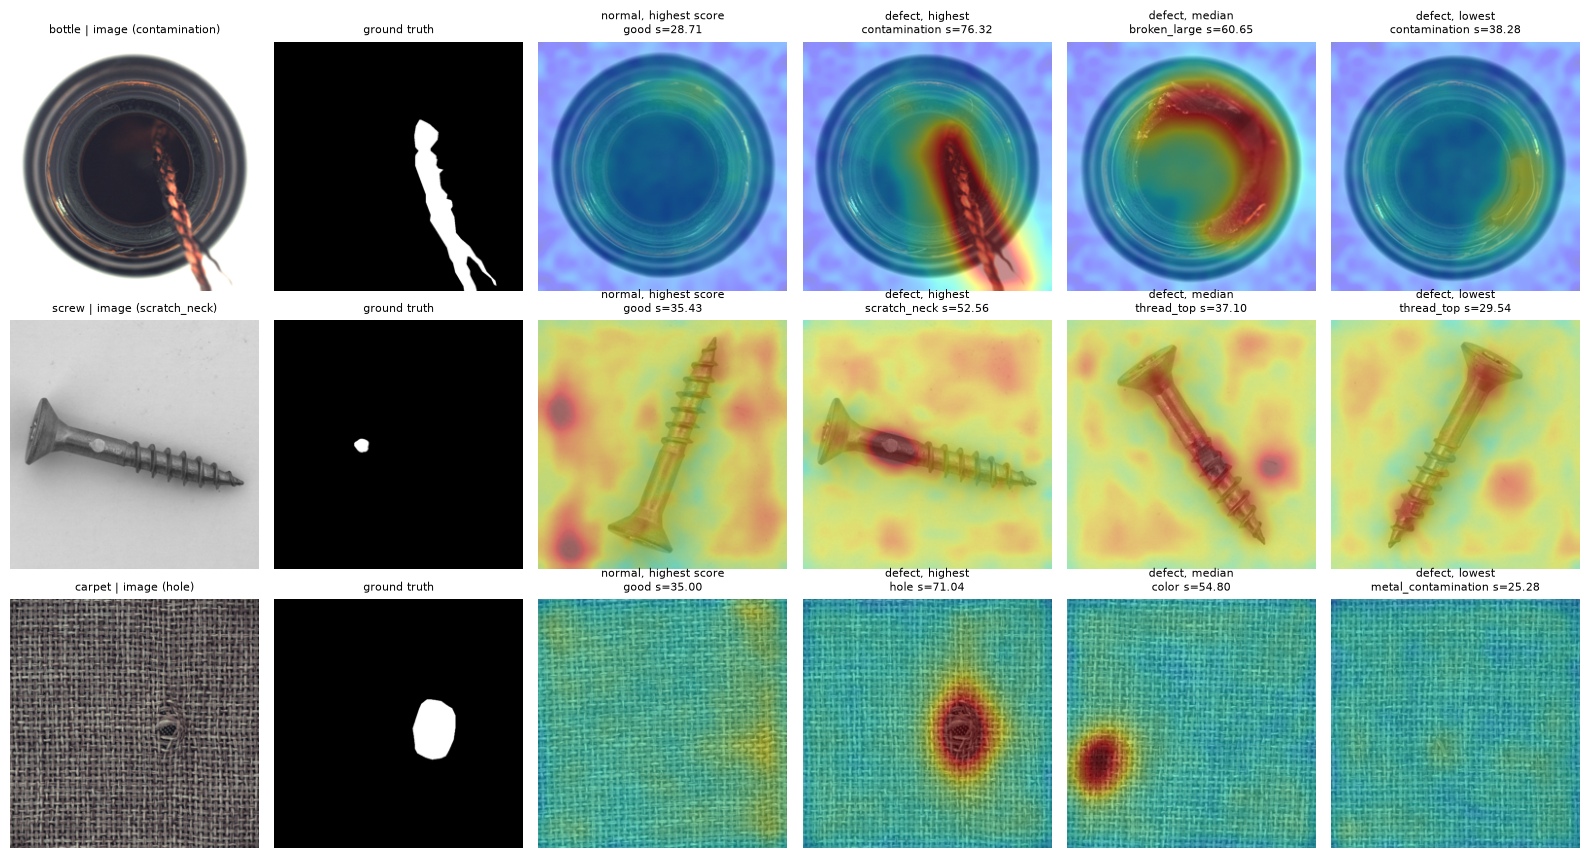

In [9]:
def overlay(ax, img, amap, title, vmax):
    ax.imshow(img); ax.imshow(amap, cmap="jet", alpha=0.45, vmin=0, vmax=vmax); ax.set_title(title, fontsize=8)
    ax.axis("off")


fig, axes = plt.subplots(3, 6, figsize=(16, 8.6))
for r, c in enumerate(FOCUS):
    z = np.load(f"results/13_runs/{c}_maps.npz")
    maps = {k.replace("__", "/"): z[k].astype(np.float32) for k in z.files}
    s = all_scores[c].sort_values("score")
    defects, goods = s[s.label == 1], s[s.label == 0]
    picks = [("normal, highest score", goods.iloc[-1]), ("defect, highest", defects.iloc[-1]),
             ("defect, median", defects.iloc[len(defects) // 2]), ("defect, lowest", defects.iloc[0])]
    vmax = float(np.percentile(np.concatenate([m.ravel() for m in maps.values()]), 99.5))
    img0 = Image.open(DATA_ROOT / c / picks[1][1]["path"]).convert("RGB").resize((256, 256))
    axes[r, 0].imshow(img0); axes[r, 0].set_title(f"{c} | image ({picks[1][1]['defect_type']})", fontsize=8)
    axes[r, 0].axis("off")
    mp = DATA_ROOT / c / "ground_truth" / picks[1][1]["defect_type"] / (Path(picks[1][1]["path"]).stem + "_mask.png")
    axes[r, 1].imshow(Image.open(mp).resize((256, 256)), cmap="gray"); axes[r, 1].set_title("ground truth", fontsize=8)
    axes[r, 1].axis("off")
    for j, (t, row) in enumerate(picks):
        img = Image.open(DATA_ROOT / c / row["path"]).convert("RGB").resize((256, 256))
        overlay(axes[r, j + 2], img, maps[row["path"]], f"{t}\n{row['defect_type']} s={row['score']:.2f}", vmax)
plt.tight_layout()
plt.savefig("results/13_heatmaps.png", dpi=90)
plt.show()

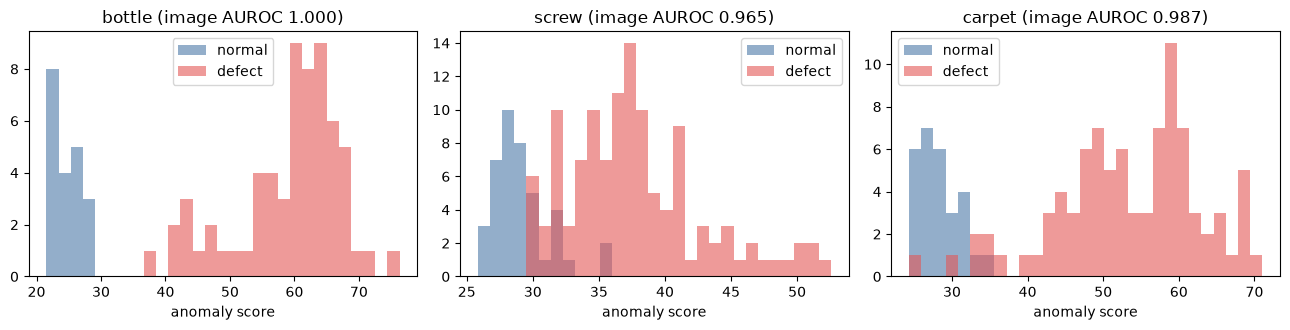

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, FOCUS):
    s = all_scores[c]
    bins = np.linspace(s.score.min(), s.score.max(), 30)
    ax.hist(s[s.label == 0].score, bins, alpha=0.6, label="normal", color="#4C78A8")
    ax.hist(s[s.label == 1].score, bins, alpha=0.6, label="defect", color="#E45756")
    ax.set_title(f"{c} (image AUROC {results['patchcore_10'][c]['image_AUROC']:.3f})"); ax.set_xlabel("anomaly score")
    ax.legend()
plt.tight_layout()
plt.savefig("results/13_score_hist.png", dpi=100)
plt.show()

In [11]:
# 결함 종류별로 보면: 자세히 보는 카테고리의 종류별 평균 점수와 검출률(정상 최고 점수보다 높은 비율)
by_type = {}
for c in FOCUS:
    s = all_scores[c]
    top_good = s[s.label == 0].score.max()
    g = s[s.label == 1].groupby("defect_type")["score"]
    by_type[c] = pd.DataFrame({"n": g.size(), "mean_score": g.mean().round(3),
                               "above_all_normal": g.apply(lambda x: round(float((x > top_good).mean()), 3))})
    print(c, "| 정상 최고 점수", round(top_good, 3)); print(by_type[c])

bottle | 정상 최고 점수 28.706
                n  mean_score  above_all_normal
defect_type                                    
broken_large   20      61.997               1.0
broken_small   22      59.247               1.0
contamination  21      55.944               1.0
screw | 정상 최고 점수 35.426
                    n  mean_score  above_all_normal
defect_type                                        
manipulated_front  24      35.524             0.542
scratch_head       24      36.554             0.667
scratch_neck       25      43.063             0.800
thread_side        23      34.050             0.304
thread_top         23      38.925             0.870
carpet | 정상 최고 점수 35.002
                      n  mean_score  above_all_normal
defect_type                                          
color                19      50.923             1.000
cut                  17      57.735             1.000
hole                 17      57.403             1.000
metal_contamination  17      49.530             0.88

## 13-4. 임계값 정하기와 현장 지표

In [12]:
thr = {c: threshold_holdout(all_scores[c]) for c in CATEGORIES}
rows = []
for c in CATEGORIES:
    for pol in ["F1최대", "미검출0"]:
        rows.append({"category": c, "policy": pol, **{k: thr[c][pol][k] for k in ["recall", "precision", "fpr", "FN", "FP"]}})
thr_table = pd.DataFrame(rows)
print(thr_table[thr_table.category.isin(FOCUS)].to_string(index=False))
print("\nB 절반의 구성:", {c: (thr[c]["B_defect"], thr[c]["B_good"]) for c in FOCUS})
print("\n15개 카테고리 평균"); print(thr_table.groupby("policy")[["recall", "precision", "fpr"]].mean().round(3))

category policy  recall  precision   fpr  FN  FP
  bottle   F1최대   1.000      1.000 0.000   0   0
  bottle   미검출0   1.000      1.000 0.000   0   0
  carpet   F1최대   0.889      1.000 0.000   5   0
  carpet   미검출0   1.000      0.804 0.786   0  11
   screw   F1최대   0.966      0.919 0.238   2   5
   screw   미검출0   0.966      0.919 0.238   2   5

B 절반의 구성: {'bottle': (32, 10), 'screw': (59, 21), 'carpet': (45, 14)}

15개 카테고리 평균
        recall  precision    fpr
policy                          
F1최대     0.952      0.967  0.091
미검출0     0.976      0.920  0.257


In [13]:
speed = pd.DataFrame({
    "bank_10": [results["patchcore_10"][c]["memory_bank"] for c in CATEGORIES],
    "bank_1": [results["patchcore_1"][c]["memory_bank"] for c in CATEGORIES],
    "fit_10": [results["patchcore_10"][c]["fit_sec"] for c in CATEGORIES],
    "fit_1": [results["patchcore_1"][c]["fit_sec"] for c in CATEGORIES],
    "ms_10": [results["patchcore_10"][c]["infer_ms_per_image"] for c in CATEGORIES],
    "ms_1": [results["patchcore_1"][c]["infer_ms_per_image"] for c in CATEGORIES],
    "gpu_gb_10": [results["patchcore_10"][c]["peak_gpu_gb"] for c in CATEGORIES],
}, index=CATEGORIES)
print(speed)
print(speed.mean().round(2))

            bank_10  bank_1  fit_10  fit_1  ms_10  ms_1  gpu_gb_10
bottle        21401    2140    89.2   16.6  23.34  7.16       1.42
cable         22937    2293   110.4   27.7  24.67  7.99       1.86
capsule       22425    2242   112.2   25.9  25.94  7.72       2.19
carpet        28672    2867   176.1   33.0  30.21  7.73       1.86
grid          27033    2703   137.2   21.7  28.29  7.62       2.16
hazelnut      40038    4003   305.0   51.1  40.14  8.87       3.35
leather       25088    2508   135.2   28.2  26.79  7.63       2.90
metal_nut     22528    2252    99.1   17.8  25.82  7.65       1.60
pill          27340    2734   163.9   28.3  30.99  8.03       2.26
screw         32768    3276   215.8   34.7  36.18  8.76       2.98
tile          23552    2355   122.7   23.7  26.28  7.53       2.84
toothbrush     6144     614    12.8    5.7  10.12  5.82       2.39
transistor    21811    2181   106.4   23.4  24.16  7.41       1.69
wood          25292    2529   135.1   26.6  27.27  7.33       

In [14]:
out = {
    "env": ENV,
    "summary": summary.reset_index().to_dict("records"),
    "image_sizes": {c: list(v) for c, v in sizes.items()}, "modes": modes,
    "defect_area_pct": area,
    "results": results,
    "table": table.reset_index().to_dict("records"),
    "mean": table.drop(columns="kind").mean().round(4).to_dict(),
    "mean_by_kind": table.groupby("kind").mean().round(4).to_dict("index"),
    "by_type": {c: v.reset_index().to_dict("records") for c, v in by_type.items()},
    "threshold": thr,
    "threshold_mean": thr_table.groupby("policy")[["recall", "precision", "fpr"]].mean().round(4).to_dict("index"),
    "speed": speed.reset_index().to_dict("records"),
}
Path("results/13_patchcore.json").write_text(json.dumps(out, ensure_ascii=False, indent=2, default=float),
                                             encoding="utf-8")

34049